# Meu Ciclo+ | Data Science — Entrega 2
## Análise exploratória das notificações de violência interpessoal e autoprovocada — SINAN

**Responsabilidade:** Abel — governança, entendimento da base e análise exploratória (EDA).  
**Fonte:** Ministério da Saúde / DATASUS — SINAN Net.  
**Recorte:** Brasil; sexo feminino; anos de notificação 2015–2024.

**Questão de investigação:** Como evoluiu a frequência anual de notificações registradas para o sexo feminino entre 2015 e 2024?

> A tabela é agregada e contém contagens de notificações, não registros individuais nem a totalidade dos episódios ocorridos. Os resultados não estimam risco individual das usuárias do aplicativo.

## 1. Proveniência e governança

**Sistema:** SINAN — Violência Interpessoal / Autoprovocada, consulta TabNet/DATASUS.  
**Portal:** https://datasus.saude.gov.br/acesso-a-informacao/doencas-e-agravos-de-notificacao-de-2007-em-diante-sinan/  
**Configuração informada na consulta:** abrangência Brasil por região, UF e município; linha *Ano da Notific*; coluna *Não ativa*; conteúdo *Frequência*; filtro *Sexo: Feminino*.  
**Período utilizado na análise:** 2015–2024. A consulta original exibiu também 2025, excluído deste CSV por estar sujeito a revisão conforme nota do portal.  
**Arquivo da análise:** `dados/brutos/sinan_feminino_2015_2024.csv`, com tabela agregada transcrita da consulta TabNet.

**A confirmar e registrar no README:** data exata de acesso, endereço da página de resultados e conferência dos valores transcritos com o portal. A exportação utilizada é uma tabela agregada, não microdados individuais.

**Privacidade:** não incluir nomes, documentos, endereços, dados de usuárias nem microdados com possibilidade de identificação.

## 2. Preparação do ambiente e leitura da tabela

Usamos `pandas` para tratamento tabular e `matplotlib` para visualização. O carregamento localiza o CSV tanto quando o kernel é iniciado de `data-science/` quanto de `data-science/notebooks/`.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

nome = "sinan_feminino_2015_2024.csv"
candidatos = [
    Path("dados/brutos") / nome,
    Path("../dados/brutos") / nome,
]
CAMINHO = next((p for p in candidatos if p.is_file()), None)
if CAMINHO is None:
    raise FileNotFoundError(
        f"CSV não encontrado. Diretório atual: {Path.cwd()}. "
        "Verifique dados/brutos/sinan_feminino_2015_2024.csv"
    )

df = pd.read_csv(CAMINHO, sep=";", encoding="utf-8-sig")
colunas_esperadas = {"ano", "frequencia"}
if not colunas_esperadas.issubset(df.columns):
    raise ValueError(f"Colunas encontradas: {list(df.columns)}; esperadas: {sorted(colunas_esperadas)}")

print("Arquivo:", CAMINHO.resolve())
print("Dimensões:", df.shape)
display(df.head())

Arquivo: /home/piassa/Documentos/GitHub/Meu-Ciclo/data-science/dados/brutos/sinan_feminino_2015_2024.csv
Dimensões: (10, 2)


,ano,frequencia
0,2015,158986
1,2016,175899
2,2017,220559
3,2018,252668
4,2019,289742


## 3. Inspeção e qualidade dos dados

Checamos dimensões, tipos, ausências, duplicações e conversão numérica. Como a tabela está agregada por ano, o diagnóstico se refere apenas a **dez linhas anuais**, não à completude dos registros originais do SINAN.

In [3]:
print("Tipos originais:")
display(df.dtypes.rename("tipo").to_frame())
print("Ausências antes da conversão:")
display(df.isna().sum().rename("ausentes").to_frame())
print("Linhas duplicadas:", int(df.duplicated().sum()))

analise = df.copy()
analise["ano"] = pd.to_numeric(analise["ano"], errors="coerce")
analise["frequencia"] = pd.to_numeric(analise["frequencia"], errors="coerce")
print("Ausências após a conversão:")
display(analise.isna().sum().rename("ausentes").to_frame())

if analise[["ano", "frequencia"]].isna().any().any():
    raise ValueError("Há valores inválidos nas colunas numéricas; revisar o CSV.")
if analise["ano"].duplicated().any():
    raise ValueError("Existem anos repetidos; revisar antes de interpretar.")
if (analise["frequencia"] < 0).any():
    raise ValueError("Frequências negativas encontradas.")

analise = analise.sort_values("ano").reset_index(drop=True)
display(analise.describe())
display(analise)

Tipos originais:


,tipo
ano,int64
frequencia,int64


Ausências antes da conversão:


,ausentes
ano,0
frequencia,0


Linhas duplicadas: 0
Ausências após a conversão:


,ausentes
ano,0
frequencia,0


,ano,frequencia
count,10.00000,10.000000
mean,2019.50000,277574.200000
std,3.02765,93141.714423
min,2015.00000,158986.000000
25%,2017.25000,223687.250000
50%,2019.50000,260776.000000
75%,2021.75000,311038.250000
max,2024.00000,437828.000000


,ano,frequencia
0,2015,158986
1,2016,175899
2,2017,220559
3,2018,252668
4,2019,289742
5,2020,233072
6,2021,268884
7,2022,318137
8,2023,419967
9,2024,437828


## 4. Exploração descritiva — evolução temporal

Visualizamos a frequência de notificações por ano, sem afirmar que a trajetória representa a incidência real de violência na população.

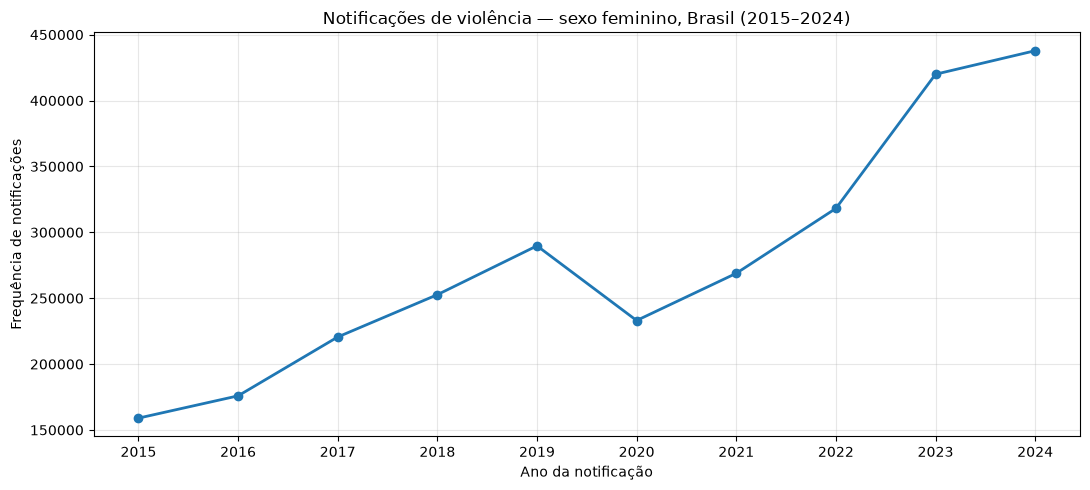

Primeiro ano: 2015 — 158,986 notificações
Último ano: 2024 — 437,828 notificações
Variação do primeiro ao último ano: 175.4%


,ano,frequencia,variacao_percentual
0,2015,158986,NaN
1,2016,175899,10.64
2,2017,220559,25.39
3,2018,252668,14.56
4,2019,289742,14.67
5,2020,233072,-19.56
6,2021,268884,15.37
7,2022,318137,18.32
8,2023,419967,32.01
9,2024,437828,4.25


In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(analise["ano"], analise["frequencia"], marker="o", linewidth=2)
ax.set_title("Notificações de violência — sexo feminino, Brasil (2015–2024)")
ax.set_xlabel("Ano da notificação")
ax.set_ylabel("Frequência de notificações")
ax.set_xticks(analise["ano"].astype(int))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

primeiro = analise.iloc[0]
ultimo = analise.iloc[-1]
variacao = (ultimo["frequencia"] / primeiro["frequencia"] - 1) * 100
print(f"Primeiro ano: {int(primeiro['ano'])} — {int(primeiro['frequencia']):,} notificações")
print(f"Último ano: {int(ultimo['ano'])} — {int(ultimo['frequencia']):,} notificações")
print(f"Variação do primeiro ao último ano: {variacao:.1f}%")
display(analise.assign(variacao_percentual=analise["frequencia"].pct_change().mul(100).round(2)))

## 5. Interpretação dos resultados

A consulta utilizada apresenta 10 registros anuais e duas variáveis, `ano` e `frequencia`. Na inspeção inicial desta **tabela agregada**, não foram observados valores ausentes nem linhas inteiramente duplicadas.

De acordo com os valores apresentados pelo DATASUS na consulta, a frequência anual passou de **158.986 notificações em 2015** para **437.828 em 2024**. Houve redução em **2020** em comparação com 2019, seguida de aumento nos anos posteriores.

**Limitações:** notificações não equivalem ao total de episódios ocorridos nem ao número de pessoas afetadas; subnotificação, mudanças nos serviços, na cobertura e nos processos de notificação podem influenciar a série. Não é possível concluir, a partir desses totais, que a ocorrência real de violência cresceu na mesma proporção. A tabela não contém recortes por UF, tipo de violência ou faixa etária.

**Conclusão da Entrega 2:** foi realizada uma EDA inicial de dados agregados do SINAN, com leitura reproduzível, inspeção da qualidade da tabela, visualização temporal e registro de limitações. O trabalho fornece uma base descritiva para análises futuras, mas não valida um modelo preditivo.

**Próximas etapas propostas:** conferir a rastreabilidade da extração, ampliar a consulta com UF e outras variáveis pertinentes e avaliar a adequação dos dados para um problema analítico defensável, antes de modelar. Não utilizar a série para inferir risco individual.